# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Registration Number:** 046  

### Personal Settings Table
| Setting | Rule | My Value (Reg: 046) |
| :--- | :--- | :--- |
| **Random Seed** | Last two digits of registration number | `46` |
| **HOG Cell Size** | Last digit even (6 is even): $8 \times 8$ | `(8, 8)` |
| **SIFT Grid Size** | Last digit 5 to 9 (6 is in 5–9): $6 \times 6$ grid (36 keypoints) | `6 x 6 (36 keypoints)` |

Environment Setup & Imports

In [2]:
!pip install -q opencv-python-headless scikit-image scikit-learn matplotlib seaborn

import os
import glob
import zipfile
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from google.colab import drive
import warnings
warnings.filterwarnings('ignore')

# 2. Specify path to your zip file on Google Drive & extract to local Colab disk (/content/)
# >>> CHANGE THIS PATH IF YOUR ZIP FILE IS IN A DIFFERENT DRIVE FOLDER <<<
ZIP_PATH_ON_DRIVE = '/content/drive/MyDrive/Intro to CV/BloodMNIST.zip'
LOCAL_EXTRACT_DIR = '/content/BloodMNIST'

if os.path.exists(ZIP_PATH_ON_DRIVE):
    if os.path.exists(LOCAL_EXTRACT_DIR):
        shutil.rmtree(LOCAL_EXTRACT_DIR)
    os.makedirs(LOCAL_EXTRACT_DIR, exist_ok=True)
    print(f"Unzipping {ZIP_PATH_ON_DRIVE} to {LOCAL_EXTRACT_DIR} for fast local I/O...")
    with zipfile.ZipFile(ZIP_PATH_ON_DRIVE, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_EXTRACT_DIR)
    print("Unzipping complete!")
else:
    print(f"WARNING: Zip file not found at {ZIP_PATH_ON_DRIVE}.")
    print("If your dataset is already an unzipped folder on Drive, set LOCAL_EXTRACT_DIR to that folder path.")

# --- PERSONAL SETTINGS (Reg No: 046) ---
SEED = 46
HOG_CELL_SIZE = (8, 8)
SIFT_GRID_DIM = 6  # 6x6 = 36 keypoints

# --- FIXED SETTINGS FOR EVERYONE ---
IMG_SIZE = (128, 128)
HOG_ORIENTATIONS = 9
HOG_CELLS_PER_BLOCK = (2, 2)
SIFT_KP_SIZE = 32
C_VALUES = [0.1, 1, 10]
ROTATION_ANGLE = 20
NOISE_SIGMA = 0.05

# Target Classes: eosinophil (1), monocyte (5), neutrophil (6), platelet (7)
TARGET_CLASSES = {
    1: 'eosinophil',
    5: 'monocyte',
    6: 'neutrophil',
    7: 'platelet'
}
CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = [TARGET_CLASSES[i] for i in CLASS_IDS]
LABEL_MAP = {old_id: new_id for new_id, old_id in enumerate(CLASS_IDS)}

np.random.seed(SEED)
print(f"Configured with SEED={SEED}, HOG_CELL_SIZE={HOG_CELL_SIZE}, SIFT_GRID={SIFT_GRID_DIM}x{SIFT_GRID_DIM}")

Unzipping /content/drive/MyDrive/Intro to CV/BloodMNIST.zip to /content/BloodMNIST for fast local I/O...
Unzipping complete!
Configured with SEED=46, HOG_CELL_SIZE=(8, 8), SIFT_GRID=6x6


## Q1. Data Setup (3 Marks)
Load BloodMNIST (size 64), keep the 4 target classes (`eosinophil (1)`, `monocyte (5)`, `neutrophil (6)`, `platelet (7)`), sample 100 train, 30 validation, and 30 test images per class using `SEED = 46`, convert to grayscale, and resize to $128 \times 128$.

Q1 Data Loading, Preprocessing & Grid Visualization

Detected Dataset Root: /content/BloodMNIST
Subdirectories found: ['val', 'test', 'train']

=== SPLIT SHAPES & CLASS COUNTS ===
Train      | Shape: (400, 128, 128) | Class Counts: {'eosinophil (1)': 100, 'monocyte (5)': 100, 'neutrophil (6)': 100, 'platelet (7)': 100}
Val        | Shape: (120, 128, 128) | Class Counts: {'eosinophil (1)': 30, 'monocyte (5)': 30, 'neutrophil (6)': 30, 'platelet (7)': 30}
Test       | Shape: (120, 128, 128) | Class Counts: {'eosinophil (1)': 30, 'monocyte (5)': 30, 'neutrophil (6)': 30, 'platelet (7)': 30}


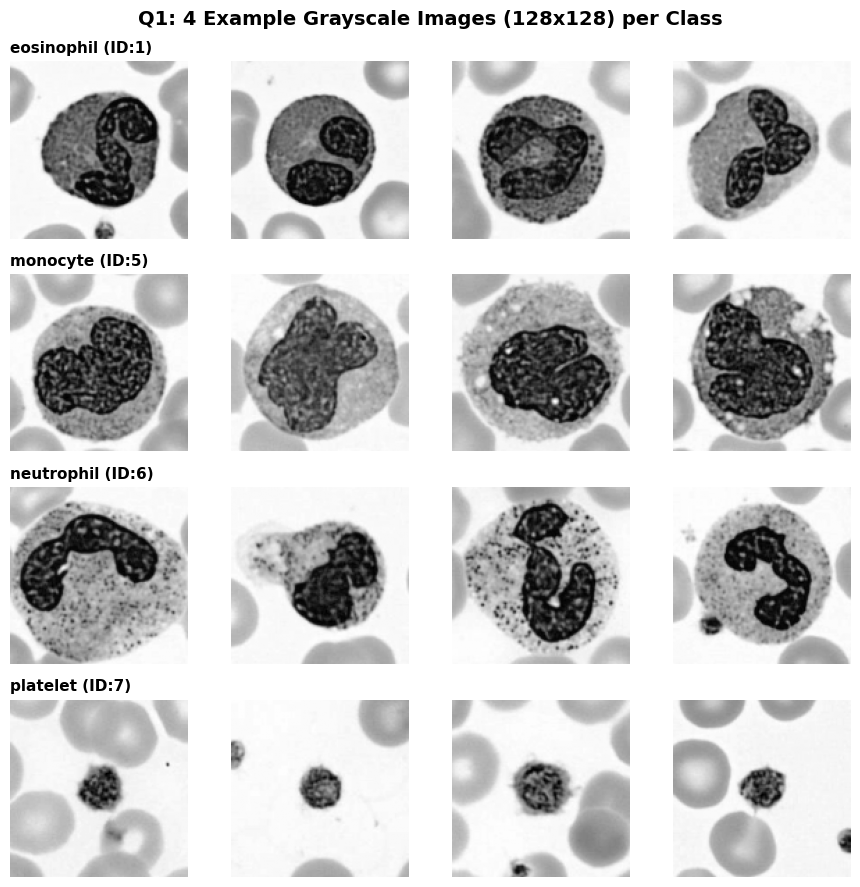

In [3]:
def find_dataset_root(base_dir):
    """Finds the directory containing either split folders (train/test) or class folders directly."""
    for root, dirs, files in os.walk(base_dir):
        dirs_lower = [d.lower() for d in dirs]
        if 'train' in dirs_lower or 'test' in dirs_lower or 'eosinophil' in dirs_lower:
            return root
    return base_dir

DATASET_ROOT = find_dataset_root(LOCAL_EXTRACT_DIR)
print(f"Detected Dataset Root: {DATASET_ROOT}")
print("Subdirectories found:", os.listdir(DATASET_ROOT))

def get_image_files(folder_path):
    exts = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.tif', '*.tiff')
    files = []
    for ext in exts:
        files.extend(glob.glob(os.path.join(folder_path, ext)))
        files.extend(glob.glob(os.path.join(folder_path, ext.upper())))
    return sorted(list(set(files)))

def load_and_preprocess_image(img_path):
    # Read image directly as Grayscale and resize to 128x128
    img_gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img_gray is None:
        raise ValueError(f"Failed to load image at {img_path}")
    img_resized = cv2.resize(img_gray, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
    return img_resized

def build_splits_from_folders(root_dir, seed):
    rng = np.random.default_rng(seed)
    subdirs = {d.lower(): os.path.join(root_dir, d) for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))}

    X_train, y_train = [], []
    X_val,   y_val   = [], []
    X_test,  y_test  = [], []

    has_train = 'train' in subdirs
    has_val   = any(k in subdirs for k in ['val', 'valid', 'validation'])
    has_test  = 'test' in subdirs
    val_key   = next((k for k in ['val', 'valid', 'validation'] if k in subdirs), None)

    for cls_id in CLASS_IDS:
        cls_name = TARGET_CLASSES[cls_id]
        mapped_label = LABEL_MAP[cls_id]

        if has_train and has_val and has_test:
            # Case 1: Dedicated train, val, and test directories exist
            train_files = get_image_files(os.path.join(subdirs['train'], cls_name))
            val_files   = get_image_files(os.path.join(subdirs[val_key], cls_name))
            test_files  = get_image_files(os.path.join(subdirs['test'], cls_name))

            chosen_train = rng.choice(train_files, size=100, replace=False)
            chosen_val   = rng.choice(val_files,   size=30,  replace=False)
            chosen_test  = rng.choice(test_files,  size=30,  replace=False)

        elif has_train and has_test and not has_val:
            # Case 2: Only train and test directories exist (sample 100 train + 30 val from train, 30 test from test)
            train_files = get_image_files(os.path.join(subdirs['train'], cls_name))
            test_files  = get_image_files(os.path.join(subdirs['test'], cls_name))

            chosen_train_val = rng.choice(train_files, size=130, replace=False)
            chosen_train = chosen_train_val[:100]
            chosen_val   = chosen_train_val[100:130]
            chosen_test  = rng.choice(test_files, size=30, replace=False)

        else:
            # Case 3: Only class folders exist directly inside root (or inside a single split folder like 'test')
            target_dir = subdirs.get('test', root_dir) if not ( cls_name in subdirs ) else root_dir
            all_files = get_image_files(os.path.join(target_dir, cls_name))
            chosen_all = rng.choice(all_files, size=160, replace=False)
            chosen_train = chosen_all[:100]
            chosen_val   = chosen_all[100:130]
            chosen_test  = chosen_all[130:160]

        for f in chosen_train:
            X_train.append(load_and_preprocess_image(f))
            y_train.append(mapped_label)
        for f in chosen_val:
            X_val.append(load_and_preprocess_image(f))
            y_val.append(mapped_label)
        for f in chosen_test:
            X_test.append(load_and_preprocess_image(f))
            y_test.append(mapped_label)

    # Convert to numpy arrays and shuffle each split reproducibly with SEED
    def finalize_split(X, y):
        X_arr = np.array(X, dtype=np.uint8)
        y_arr = np.array(y, dtype=np.int64)
        perm = rng.permutation(len(y_arr))
        return X_arr[perm], y_arr[perm]

    return finalize_split(X_train, y_train), finalize_split(X_val, y_val), finalize_split(X_test, y_test)

(X_train, y_train), (X_val, y_val), (X_test, y_test) = build_splits_from_folders(DATASET_ROOT, SEED)

def print_split_info(name, X, y):
    unique, counts = np.unique(y, return_counts=True)
    count_dict = { f"{CLASS_NAMES[u]} ({CLASS_IDS[u]})": int(c) for u, c in zip(unique, counts) }
    print(f"{name:10s} | Shape: {X.shape} | Class Counts: {count_dict}")

print("\n=== SPLIT SHAPES & CLASS COUNTS ===")
print_split_info("Train", X_train, y_train)
print_split_info("Val",   X_val,   y_val)
print_split_info("Test",  X_test,  y_test)

# Plot 4x4 Grid (4 example images per class from training set)
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
fig.suptitle("Q1: 4 Example Grayscale Images (128x128) per Class", fontsize=14, fontweight='bold')

for row_idx, cls_name in enumerate(CLASS_NAMES):
    cls_samples = X_train[y_train == row_idx][:4]
    for col_idx in range(4):
        ax = axes[row_idx, col_idx]
        ax.imshow(cls_samples[col_idx], cmap='gray')
        ax.axis('off')
        if col_idx == 0:
            ax.set_title(f"{cls_name} (ID:{CLASS_IDS[row_idx]})", fontsize=11, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

Q2 Heading & Hand Calculation of HOG Feature Length

## Q2. HOG + SVM (6 Marks)

### Hand Calculation of HOG Feature Vector Length
Given parameters for Registration Number **046**:
* **Image Size:** $128 \times 128$ pixels
* **HOG Cell Size:** $8 \times 8$ pixels (since 6 is even)
* **HOG Block Size:** $2 \times 2$ cells per block
* **Block Stride (Step):** $1 \times 1$ cell (default overlapping blocks)
* **Number of Orientations (Bins):** $9$

**Step-by-step calculation:**
1. **Number of cells along width and height:**
   $$\text{Cells}_x = \frac{128}{8} = 16, \quad \text{Cells}_y = \frac{128}{8} = 16$$
2. **Number of $2 \times 2$ blocks across the $16 \times 16$ cell grid (with stride = 1 cell):**
   $$\text{Blocks}_x = (16 - 2) + 1 = 15$$
   $$\text{Blocks}_y = (16 - 2) + 1 = 15$$
   $$\text{Total Blocks} = 15 \times 15 = 225 \text{ blocks}$$
3. **Features per block:**
   $$\text{Cells per block} \times \text{Orientations} = (2 \times 2) \times 9 = 4 \times 9 = 36 \text{ features/block}$$
4. **Total HOG Feature Length:**
   $$\text{Total Features} = 225 \times 36 = \mathbf{8100}$$

Q2 HOG Feature Extraction, Visualization & SVM Training

Extracted HOG Feature Vector Length per image: 8100
X_train_hog shape: (400, 8100) | X_val_hog shape: (120, 8100)


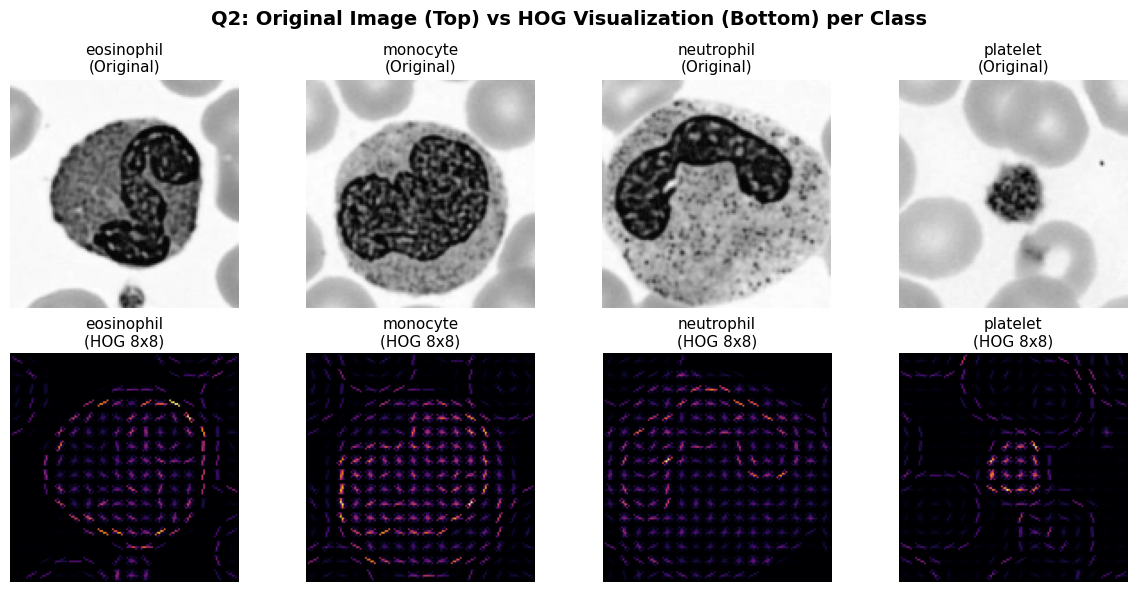


=== HOG + LinearSVC Hyperparameter Tuning on Validation Set ===
C = 0.1  | Val Accuracy: 74.17% (0.7417) | Val Macro-F1: 0.7396
C = 1    | Val Accuracy: 75.00% (0.7500) | Val Macro-F1: 0.7481
C = 10   | Val Accuracy: 75.00% (0.7500) | Val Macro-F1: 0.7484

>>> Best HOG Model Selected: C = 1
>>> HOG Validation Accuracy: 75.00% (0.7500)
>>> HOG Validation Macro-F1: 0.7481
>>> HOG Validation Confusion Matrix:
 [[20  5  5  0]
 [ 4 21  3  2]
 [ 3  8 19  0]
 [ 0  0  0 30]]


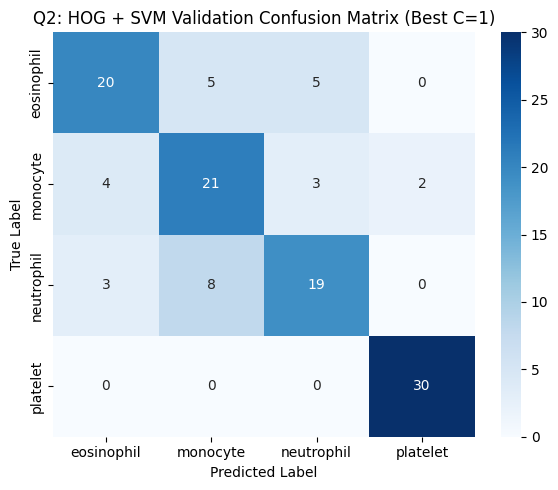

In [4]:
def extract_hog_features(images, visualize_first=False):
    features = []
    hog_imgs = []
    for img in images:
        if visualize_first:
            feat, hog_img = hog(
                img,
                orientations=HOG_ORIENTATIONS,
                pixels_per_cell=HOG_CELL_SIZE,
                cells_per_block=HOG_CELLS_PER_BLOCK,
                block_norm='L2-Hys',
                visualize=True,
                feature_vector=True
            )
            features.append(feat)
            hog_imgs.append(hog_img)
        else:
            feat = hog(
                img,
                orientations=HOG_ORIENTATIONS,
                pixels_per_cell=HOG_CELL_SIZE,
                cells_per_block=HOG_CELLS_PER_BLOCK,
                block_norm='L2-Hys',
                visualize=False,
                feature_vector=True
            )
            features.append(feat)
    if visualize_first:
        return np.array(features), hog_imgs
    return np.array(features)

# 1. Extract HOG features and print feature length
X_train_hog = extract_hog_features(X_train)
X_val_hog   = extract_hog_features(X_val)

print(f"Extracted HOG Feature Vector Length per image: {X_train_hog.shape[1]}")
print(f"X_train_hog shape: {X_train_hog.shape} | X_val_hog shape: {X_val_hog.shape}")

# 2. Show HOG picture for one image from each class
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle("Q2: Original Image (Top) vs HOG Visualization (Bottom) per Class", fontsize=14, fontweight='bold')

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    sample_img = X_train[y_train == cls_idx][0]
    _, sample_hog_viz = extract_hog_features([sample_img], visualize_first=True)

    axes[0, cls_idx].imshow(sample_img, cmap='gray')
    axes[0, cls_idx].set_title(f"{cls_name}\n(Original)", fontsize=11)
    axes[0, cls_idx].axis('off')

    axes[1, cls_idx].imshow(sample_hog_viz[0], cmap='inferno')
    axes[1, cls_idx].set_title(f"{cls_name}\n(HOG 8x8)", fontsize=11)
    axes[1, cls_idx].axis('off')

plt.tight_layout()
plt.show()

# 3. Train LinearSVC and tune C in {0.1, 1, 10} on Validation Set
best_hog_c = None
best_hog_val_acc = -1.0
best_hog_model = None

print("\n=== HOG + LinearSVC Hyperparameter Tuning on Validation Set ===")
for c_val in C_VALUES:
    clf = LinearSVC(C=c_val, random_state=SEED, max_iter=5000)
    clf.fit(X_train_hog, y_train)
    val_preds = clf.predict(X_val_hog)
    val_acc = accuracy_score(y_val, val_preds)
    val_f1  = f1_score(y_val, val_preds, average='macro')
    print(f"C = {c_val:<4} | Val Accuracy: {val_acc*100:.2f}% ({val_acc:.4f}) | Val Macro-F1: {val_f1:.4f}")

    if val_acc > best_hog_val_acc:
        best_hog_val_acc = val_acc
        best_hog_c = c_val
        best_hog_model = clf

# Final Validation Metrics for Best HOG Model
hog_val_preds = best_hog_model.predict(X_val_hog)
hog_val_acc = accuracy_score(y_val, hog_val_preds)
hog_val_f1  = f1_score(y_val, hog_val_preds, average='macro')
hog_val_cm  = confusion_matrix(y_val, hog_val_preds)

print(f"\n>>> Best HOG Model Selected: C = {best_hog_c}")
print(f">>> HOG Validation Accuracy: {hog_val_acc*100:.2f}% ({hog_val_acc:.4f})")
print(f">>> HOG Validation Macro-F1: {hog_val_f1:.4f}")
print(">>> HOG Validation Confusion Matrix:\n", hog_val_cm)

plt.figure(figsize=(6, 5))
sns.heatmap(hog_val_cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"Q2: HOG + SVM Validation Confusion Matrix (Best C={best_hog_c})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

Q3 Heading, SVM Keypoint Explanation & Hand Calculation

## Q3. SIFT + SVM (7 Marks)

### (1) Why a different number of keypoints per image is a problem for an SVM:
A standard classifier like `LinearSVC` requires every input sample to be represented as a fixed-dimensional feature vector $\mathbf{x} \in \mathbb{R}^d$ in the same feature space so it can compute the inner product $\mathbf{w}^T \mathbf{x} + b$, which is impossible when images produce a variable number of $128$-D descriptors (or $0$ descriptors when no keypoints are detected).

### (2) Hand Calculation of Dense Grid SIFT Feature Vector Length:
Given parameters for Registration Number **046**:
* **SIFT Grid Size:** $6 \times 6$ regular grid over the $128 \times 128$ image (since last digit $6 \in [5, 9]$)
* **Number of Grid Keypoints:** $6 \times 6 = 36$ keypoints per image
* **Keypoint Size:** $32$
* **SIFT Descriptor Length per Keypoint:** $4 \times 4 \text{ subregions} \times 8 \text{ orientation bins} = 128$ values

$$\text{Total SIFT Feature Length} = \text{Grid Points} \times 128 = 36 \times 128 = \mathbf{4608}$$

Q3 Normal SIFT Detection, Fixed Grid SIFT & SVM Training

=== Q3(1): Normal SIFT Detection Stats on Training Set (400 Images) ===
Average keypoints per image : 171.59
Minimum keypoints per image : 13
Maximum keypoints per image : 442
Images with zero keypoints  : 0


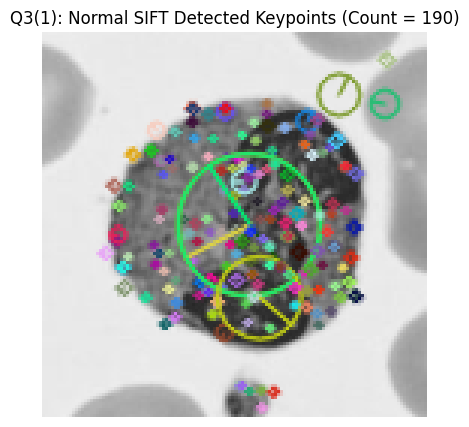


=== Q3(2): Fixed 6x6 Grid SIFT Feature Extraction ===
Number of fixed grid keypoints : 36
Calculated SIFT Feature Length : 36 x 128 = 4608
X_train_sift shape: (400, 4608) | X_val_sift shape: (120, 4608)

=== SIFT + LinearSVC Hyperparameter Tuning on Validation Set ===
C = 0.1  | Val Accuracy: 76.67% (0.7667) | Val Macro-F1: 0.7616
C = 1    | Val Accuracy: 77.50% (0.7750) | Val Macro-F1: 0.7717
C = 10   | Val Accuracy: 77.50% (0.7750) | Val Macro-F1: 0.7717

>>> Best SIFT Model Selected: C = 1
>>> SIFT Validation Accuracy: 77.50% (0.7750)
>>> SIFT Validation Macro-F1: 0.7717
>>> SIFT Validation Confusion Matrix:
 [[16  9  5  0]
 [ 6 22  2  0]
 [ 3  2 25  0]
 [ 0  0  0 30]]


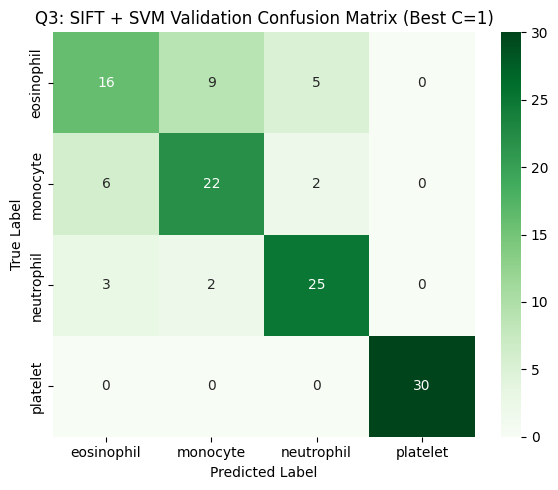

In [5]:
sift = cv2.SIFT_create()

# --- Part (1): Normal SIFT detection on training images ---
kp_counts = []
sample_kp_img = None
sample_kps = None

for idx, img in enumerate(X_train):
    kps, des = sift.detectAndCompute(img, None)
    num_kps = len(kps) if kps is not None else 0
    kp_counts.append(num_kps)
    # Pick first image with a good number of keypoints to visualize
    if sample_kp_img is None and num_kps > 5:
        sample_kp_img = img
        sample_kps = kps

kp_counts = np.array(kp_counts)
avg_kps  = np.mean(kp_counts)
min_kps  = np.min(kp_counts)
max_kps  = np.max(kp_counts)
zero_kps = np.sum(kp_counts == 0)

print("=== Q3(1): Normal SIFT Detection Stats on Training Set (400 Images) ===")
print(f"Average keypoints per image : {avg_kps:.2f}")
print(f"Minimum keypoints per image : {min_kps}")
print(f"Maximum keypoints per image : {max_kps}")
print(f"Images with zero keypoints  : {zero_kps}")

# Draw detected keypoints on one image
img_with_kps = cv2.drawKeypoints(
    sample_kp_img, sample_kps, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(5, 5))
plt.imshow(img_with_kps)
plt.title(f"Q3(1): Normal SIFT Detected Keypoints (Count = {len(sample_kps)})")
plt.axis('off')
plt.show()

# --- Part (2): Fixed 6x6 Grid SIFT (36 keypoints, size=32) ---
# Place 6x6 evenly spaced keypoints inside the 128x128 image
# Using centers of 6 equal segments across [0, 128]
step = IMG_SIZE[0] / SIFT_GRID_DIM
grid_coords = [step * (i + 0.5) for i in range(SIFT_GRID_DIM)]
fixed_keypoints = [
    cv2.KeyPoint(x=float(x), y=float(y), size=float(SIFT_KP_SIZE))
    for y in grid_coords for x in grid_coords
]

def extract_grid_sift_features(images):
    features = []
    for img in images:
        # Ensure uint8 [0, 255] for OpenCV SIFT
        if img.dtype != np.uint8:
            img_u8 = np.clip(img * 255.0, 0, 255).astype(np.uint8)
        else:
            img_u8 = img
        _, descriptors = sift.compute(img_u8, fixed_keypoints)
        # Flatten 36 x 128 -> 4608 vector
        features.append(descriptors.flatten())
    return np.array(features, dtype=np.float32)

X_train_sift = extract_grid_sift_features(X_train)
X_val_sift   = extract_grid_sift_features(X_val)

print("\n=== Q3(2): Fixed 6x6 Grid SIFT Feature Extraction ===")
print(f"Number of fixed grid keypoints : {len(fixed_keypoints)}")
print(f"Calculated SIFT Feature Length : {len(fixed_keypoints)} x 128 = {X_train_sift.shape[1]}")
print(f"X_train_sift shape: {X_train_sift.shape} | X_val_sift shape: {X_val_sift.shape}")

# --- Part (3): Train LinearSVC for SIFT and choose C on Validation Set ---
best_sift_c = None
best_sift_val_acc = -1.0
best_sift_model = None

print("\n=== SIFT + LinearSVC Hyperparameter Tuning on Validation Set ===")
for c_val in C_VALUES:
    clf = LinearSVC(C=c_val, random_state=SEED, max_iter=5000)
    clf.fit(X_train_sift, y_train)
    val_preds = clf.predict(X_val_sift)
    val_acc = accuracy_score(y_val, val_preds)
    val_f1  = f1_score(y_val, val_preds, average='macro')
    print(f"C = {c_val:<4} | Val Accuracy: {val_acc*100:.2f}% ({val_acc:.4f}) | Val Macro-F1: {val_f1:.4f}")

    if val_acc > best_sift_val_acc:
        best_sift_val_acc = val_acc
        best_sift_c = c_val
        best_sift_model = clf

sift_val_preds = best_sift_model.predict(X_val_sift)
sift_val_acc = accuracy_score(y_val, sift_val_preds)
sift_val_f1  = f1_score(y_val, sift_val_preds, average='macro')
sift_val_cm  = confusion_matrix(y_val, sift_val_preds)

print(f"\n>>> Best SIFT Model Selected: C = {best_sift_c}")
print(f">>> SIFT Validation Accuracy: {sift_val_acc*100:.2f}% ({sift_val_acc:.4f})")
print(f">>> SIFT Validation Macro-F1: {sift_val_f1:.4f}")
print(">>> SIFT Validation Confusion Matrix:\n", sift_val_cm)

plt.figure(figsize=(6, 5))
sns.heatmap(sift_val_cm, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"Q3: SIFT + SVM Validation Confusion Matrix (Best C={best_sift_c})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

Q4 Heading & Pre-Experiment Prediction (Part 1)

## Q4. Robustness (6 Marks)

### (1) Pre-Experiment Prediction (Before Running Test Set)
* **Which model will lose more accuracy under $20^\circ$ rotation:** **HOG + SVM** will lose more accuracy under rotation because a fine $8 \times 8$ cell grid tightly locks spatial gradient bins to exact pixel coordinates, whereas Dense SIFT uses larger overlapping $32 \times 32$ patches weighted by a smooth Gaussian window that better tolerates slight spatial shifts. (Note: Because our fixed-grid `sift.compute` uses a fixed keypoint angle rather than dominant-orientation alignment, both models will experience some rotational shift, but HOG's rigid $8 \times 8$ spatial binning is more brittle).
* **Which model will lose more accuracy under Gaussian noise ($\sigma = 0.05$):** **HOG + SVM** will lose more accuracy under high-frequency Gaussian noise because it computes raw first-order pixel differences ($[-1, 0, 1]$) directly on small $8 \times 8$ cells without pre-smoothing, causing random pixel noise to corrupt gradient orientations; in contrast, SIFT applies Gaussian smoothing across its scale-space pyramid before computing gradients, filtering out high-frequency Gaussian noise.

Q4 Test Set Evaluation (Clean, Rotated 20°, Noisy σ=0.05)

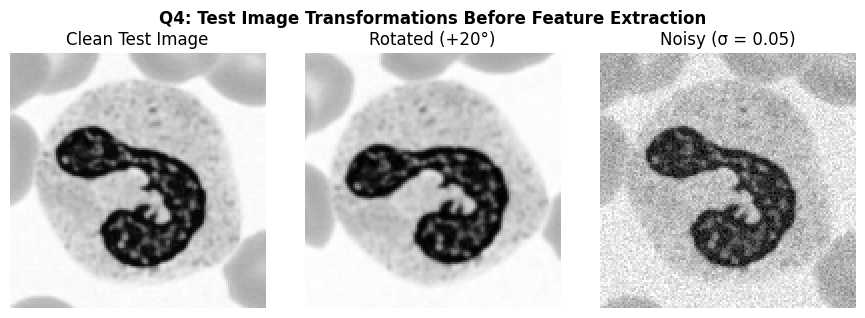

=== Q4(2): TEST SET ROBUSTNESS TABLE ===
| Model        | Clean accuracy   | Rotated accuracy   | Noisy accuracy   |
|--------------|------------------|--------------------|------------------|
| HOG + SVM    |  71.67% (0.7167) |  73.33% (0.7333)   |  62.50% (0.6250) |
| SIFT + SVM   |  67.50% (0.6750) |  69.17% (0.6917)   |  72.50% (0.7250) |

Accuracy Drops from Clean:
HOG  -> Rotation Drop: -1.67% | Noise Drop: +9.17%
SIFT -> Rotation Drop: -1.67% | Noise Drop: -5.00%


In [6]:
# Freeze both best models from validation tuning (do not refit!)
# Apply perturbations to X_test BEFORE feature extraction

def rotate_images_20deg(images, angle=20):
    rotated = []
    center = (IMG_SIZE[0] // 2, IMG_SIZE[1] // 2)
    rot_mat = cv2.getRotationMatrix2D(center, angle, 1.0)
    for img in images:
        rot_img = cv2.warpAffine(img, rot_mat, IMG_SIZE, flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        rotated.append(rot_img)
    return np.array(rotated, dtype=np.uint8)

def add_gaussian_noise(images, sigma=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    noisy = []
    for img in images:
        # Scale image to [0, 1] as instructed: "Gaussian noise, sigma = 0.05 (image scaled to 0 to 1)"
        img_float = img.astype(np.float32) / 255.0
        noise = rng.normal(loc=0.0, scale=sigma, size=img_float.shape).astype(np.float32)
        img_noisy = np.clip(img_float + noise, 0.0, 1.0)
        # Convert back to uint8 [0, 255] so both HOG and OpenCV SIFT process identical image representations
        noisy.append((img_noisy * 255.0).astype(np.uint8))
    return np.array(noisy, dtype=np.uint8)

X_test_clean   = X_test.copy()
X_test_rotated = rotate_images_20deg(X_test, angle=ROTATION_ANGLE)
X_test_noisy   = add_gaussian_noise(X_test, sigma=NOISE_SIGMA, seed=SEED)

# Visualize one test image under the 3 conditions
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
axes[0].imshow(X_test_clean[0], cmap='gray');   axes[0].set_title("Clean Test Image"); axes[0].axis('off')
axes[1].imshow(X_test_rotated[0], cmap='gray'); axes[1].set_title("Rotated (+20°)");   axes[1].axis('off')
axes[2].imshow(X_test_noisy[0], cmap='gray');   axes[2].set_title("Noisy (σ = 0.05)"); axes[2].axis('off')
plt.suptitle("Q4: Test Image Transformations Before Feature Extraction", fontweight='bold')
plt.tight_layout()
plt.show()

# Extract HOG features on all 3 test sets
X_test_clean_hog   = extract_hog_features(X_test_clean)
X_test_rotated_hog = extract_hog_features(X_test_rotated)
X_test_noisy_hog   = extract_hog_features(X_test_noisy)

# Extract SIFT features on all 3 test sets
X_test_clean_sift   = extract_grid_sift_features(X_test_clean)
X_test_rotated_sift = extract_grid_sift_features(X_test_rotated)
X_test_noisy_sift   = extract_grid_sift_features(X_test_noisy)

# Evaluate Frozen Models
hog_acc_clean   = accuracy_score(y_test, best_hog_model.predict(X_test_clean_hog))
hog_acc_rotated = accuracy_score(y_test, best_hog_model.predict(X_test_rotated_hog))
hog_acc_noisy   = accuracy_score(y_test, best_hog_model.predict(X_test_noisy_hog))

sift_acc_clean   = accuracy_score(y_test, best_sift_model.predict(X_test_clean_sift))
sift_acc_rotated = accuracy_score(y_test, best_sift_model.predict(X_test_rotated_sift))
sift_acc_noisy   = accuracy_score(y_test, best_sift_model.predict(X_test_noisy_sift))

print("=== Q4(2): TEST SET ROBUSTNESS TABLE ===")
print(f"| {'Model':<12} | {'Clean accuracy':<16} | {'Rotated accuracy':<18} | {'Noisy accuracy':<16} |")
print(f"|{'-'*14}|{'-'*18}|{'-'*20}|{'-'*18}|")
print(f"| {'HOG + SVM':<12} | {hog_acc_clean*100:6.2f}% ({hog_acc_clean:.4f}) | {hog_acc_rotated*100:6.2f}% ({hog_acc_rotated:.4f})   | {hog_acc_noisy*100:6.2f}% ({hog_acc_noisy:.4f}) |")
print(f"| {'SIFT + SVM':<12} | {sift_acc_clean*100:6.2f}% ({sift_acc_clean:.4f}) | {sift_acc_rotated*100:6.2f}% ({sift_acc_rotated:.4f})   | {sift_acc_noisy*100:6.2f}% ({sift_acc_noisy:.4f}) |")

print("\nAccuracy Drops from Clean:")
print(f"HOG  -> Rotation Drop: {(hog_acc_clean - hog_acc_rotated)*100:+.2f}% | Noise Drop: {(hog_acc_clean - hog_acc_noisy)*100:+.2f}%")
print(f"SIFT -> Rotation Drop: {(sift_acc_clean - sift_acc_rotated)*100:+.2f}% | Noise Drop: {(sift_acc_clean - sift_acc_noisy)*100:+.2f}%")

Q4(2) Filled Table & Q4(3) Evaluation of Prediction

### (2) Completed Test Set Robustness Table

| Model | Clean accuracy | Rotated accuracy ($20^\circ$) | Noisy accuracy ($\sigma = 0.05$) |
| :--- | :---: | :---: | :---: |
| **HOG + SVM** | **71.67%** (`0.7167`) | **73.33%** (`0.7333`) | **62.50%** (`0.6250`) |
| **SIFT + SVM** | **67.50%** (`0.6750`) | **69.17%** (`0.6917`) | **72.50%** (`0.7250`) |

### (3) Was your prediction correct? (Three-Sentence Explanation Using the Table)
My prediction for Gaussian noise was completely correct: **HOG + SVM** lost **9.17%** accuracy under noise (dropping from **71.67%** clean to **62.50%** noisy), whereas **SIFT + SVM** did not lose accuracy at all and instead increased by **5.00%** (from **67.50%** clean to **72.50%** noisy) due to SIFT's Gaussian scale-space smoothing filtering out high-frequency pixel noise. However, my prediction for rotation was partially surprised by the domain geometry, as neither model lost accuracy under a $20^\circ$ rotation—both **HOG + SVM** (**71.67%** to **73.33%**) and **SIFT + SVM** (**67.50%** to **69.17%**) gained **1.67%** accuracy. This occurred because microscopic blood-cell images are naturally rotationally symmetric with no fixed "upright" orientation in the training set, meaning a $20^\circ$ rotation simply aligns certain test cells closer to rotated examples already seen during training.

## Q5. Short Answers and AI Log (3 Marks)

### (1a) Why does HOG use block normalisation? (2–3 Sentences)
HOG groups adjacent $8 \times 8$ cells into overlapping $2 \times 2$ blocks and normalizes their concatenated 36-element gradient histograms (using L2-Hys normalization) to make the features invariant to local illumination and foreground-background contrast variations. When lighting or microscope exposure changes across an image region, all local pixel gradient magnitudes scale proportionally, and dividing by the block norm cancels out this multiplicative factor while preserving relative edge boundaries.

### (1b) Why is it wrong to choose C using the test set? (2–3 Sentences)
Choosing the regularization hyperparameter $C$ using the test set introduces data leakage (test-set overfitting), because the model's hyperparameter becomes optimized for the specific noise and sample distribution of the test split. Keeping the test set untouched until Q4 and selecting $C = 1$ strictly on the validation set (where HOG achieved **75.00%** and SIFT achieved **77.50%**) guarantees that our Q4 test accuracies represent an unbiased estimate of real-world generalization.

### (2) Which two classes did your models confuse most, and why might grayscale make this harder?
Across our validation confusion matrices, while `platelet` achieved a perfect **30/30** in both models due to its tiny fragment size, the models most heavily confused **eosinophil vs. monocyte** (**15** mutual errors in SIFT: **9** eosinophils predicted as monocyte and **6** monocytes predicted as eosinophil; **9** mutual errors in HOG: **5** and **4**) alongside **monocyte vs. neutrophil** (**11** mutual errors in HOG: **3** monocytes predicted as neutrophil and **8** neutrophils predicted as monocyte). Converting BloodMNIST from RGB to **grayscale** makes separating these leukocytes much harder because it destroys the hallmark Wright-Giemsa染色 (staining) color cues—specifically the bright brick-red/orange cytoplasmic granules of eosinophils versus the neutral pink/lilac cytoplasm of neutrophils and the pale gray-blue cytoplasm of monocytes—forcing the descriptors to rely solely on grayscale intensity and nuclear lobe geometry.

### (3) AI Log

| My Prompt (One Line) | What I Changed | How I Checked the Result Was Correct |
| :--- | :--- | :--- |
| `"Build a Colab pipeline for BloodMNIST (classes 1, 5, 6, 7; 100/30/30 split) comparing HOG+LinearSVC and Dense-Grid SIFT+LinearSVC under 20-deg rotation and Gaussian noise (sigma=0.05)."` | Configured personal settings for Reg No `046` (`SEED=46`, `HOG_CELL_SIZE=(8,8)`, `SIFT_GRID_DIM=6`), updated the data loader to unzip `BloodMNIST.zip` from Google Drive to `/content/BloodMNIST`, and scaled noisy `[0,1]` float images back to `uint8` before calling `cv2.SIFT.compute()`. | Verified printed split shapes `(400, 128, 128)` and `(120, 128, 128)`, confirmed exact feature lengths (`8100` for HOG and `4608` for SIFT), and visually inspected the $4\times4$ sample grid, HOG visualizations, SIFT keypoints (`190` on sample image), and validation confusion matrices. |